In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
data = load_diabetes(as_frame=True)
df = data.frame.copy()

print("Dataset:", data.DESCR.splitlines()[0])
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())
print("\\nData types:")
print(df.dtypes)
print("\\nSummary statistics:")
display(df.describe().T)
print("\\nMissing values:")
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset: .. _diabetes_dataset:
Rows: 442 | Columns: 11


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


\nData types:
age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object
\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


\nMissing values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64
Duplicate rows: 0


In [13]:
features = ["bmi", "bp", "s5", "s6"]
target = "target"

print("Selected features:", features)
print("Target:", target)
print("Missing in selected data:", df[features + [target]].isna().sum().sum())

Selected features: ['bmi', 'bp', 's5', 's6']
Target: target
Missing in selected data: 0


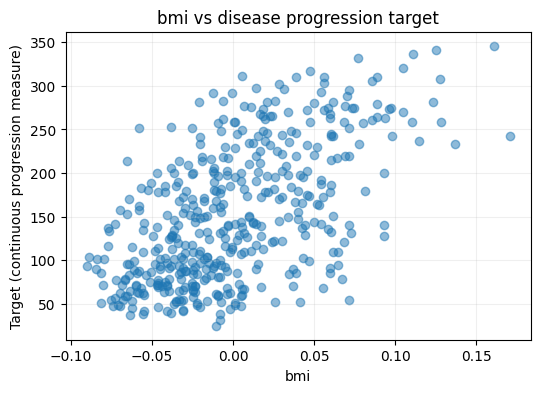

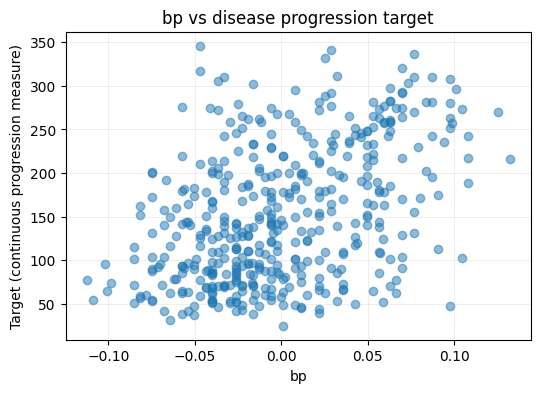

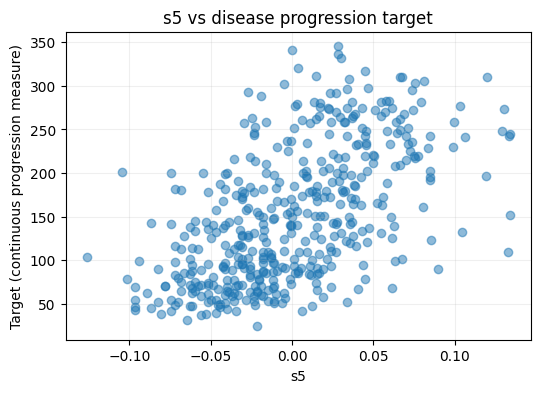

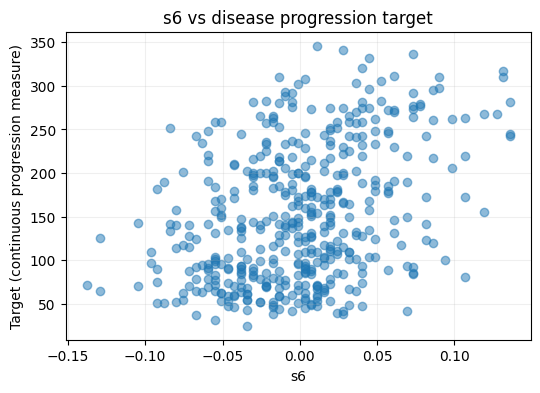

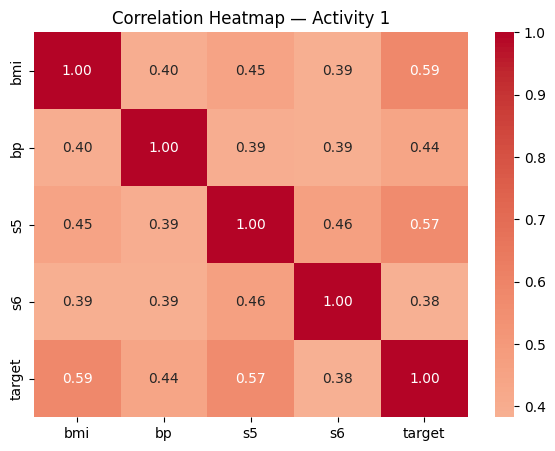

Feature-target correlations:


,target
bmi,0.586450
s5,0.565883
bp,0.441482
s6,0.382483


In [14]:
for col in features:
    plt.figure(figsize=(6,4))
    plt.scatter(df[col], df[target], alpha=0.5)
    plt.title(f"{col} vs disease progression target")
    plt.xlabel(col)
    plt.ylabel("Target (continuous progression measure)")
    plt.grid(alpha=0.2)
    plt.show()

corr = df[features + [target]].corr()
plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap — Activity 1")
plt.show()

print("Feature-target correlations:")
display(corr[target].drop(target).sort_values(key=lambda s: s.abs(), ascending=False))

In [15]:
small = df[["bmi", "bp", "target"]].head(5).copy()
X_small = np.column_stack([np.ones(len(small)), small["bmi"].values, small["bp"].values])
y_small = small["target"].values

XtX = X_small.T @ X_small
Xty = X_small.T @ y_small
b_manual = np.linalg.solve(XtX, Xty)

display(small)
print("Design matrix X (columns: 1, BMI, BP):\\n", X_small)
print("\\nTarget vector y:\\n", y_small)
print("\\nX^T X:\\n", XtX)
print("\\nX^T y:\\n", Xty)
print("\\nManual coefficients [b0, b1, b2]:\\n", b_manual)
print(f"Manual fitted equation: y = {b_manual[0]:.4f} + ({b_manual[1]:.4f})*BMI + ({b_manual[2]:.4f})*BP")

# Predict first sample and calculate residual (actual - predicted)
pred_first = X_small[0] @ b_manual
res_first = y_small[0] - pred_first
print(f"First observation: actual={y_small[0]:.4f}, predicted={pred_first:.4f}, residual={res_first:.4f}")

,bmi,bp,target
0,0.061696,0.021872,151.0
1,-0.051474,-0.026328,75.0
2,0.044451,-0.005670,141.0
3,-0.011595,-0.036656,206.0
4,-0.036385,0.021872,135.0


Design matrix X (columns: 1, BMI, BP):\n [[ 1.          0.06169621  0.02187239]
 [ 1.         -0.05147406 -0.02632753]
 [ 1.          0.04445121 -0.00567042]
 [ 1.         -0.01159501 -0.03665608]
 [ 1.         -0.03638469  0.02187239]]
\nTarget vector y:\n [151.  75. 141. 206. 135.]
\nX^T X:\n [[ 5.00000000e+00  6.69365191e-03 -2.49092605e-02]
 [ 6.69365191e-03  9.89020143e-03  2.08177864e-03]
 [-2.49092605e-02  2.08177864e-03  3.02576320e-03]]
\nX^T y:\n [708.           4.42268724  -4.0697446 ]
\nManual coefficients [b0, b1, b2]:\n [ 138.3617448   464.10486371 -525.29538476]
Manual fitted equation: y = 138.3617 + (464.1049)*BMI + (-525.2954)*BP
First observation: actual=151.0000, predicted=155.5058, residual=-4.5058


In [16]:
manual_verify = LinearRegression()
manual_verify.fit(small[["bmi", "bp"]], small["target"])
print("Library intercept:", manual_verify.intercept_)
print("Library coefficients:", manual_verify.coef_)
print("Manual intercept:", b_manual[0])
print("Manual coefficients:", b_manual[1:])

Library intercept: 138.36174480441025
Library coefficients: [ 464.10486371 -525.29538476]
Manual intercept: 138.36174480441028
Manual coefficients: [ 464.10486371 -525.29538476]


In [17]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

train_corr = X_train.join(y_train).corr()[target].drop(target)
best_feature = train_corr.abs().idxmax()
print("Strongest training feature by absolute correlation:", best_feature)

single_model = LinearRegression().fit(X_train[[best_feature]], y_train)
multi_model = LinearRegression().fit(X_train, y_train)

print("\\nSingle-feature model:")
print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])
print("Multiple-feature model:")
print("Intercept:", multi_model.intercept_)
print(pd.Series(multi_model.coef_, index=features, name="Coefficient"))

Train rows: 353 | Test rows: 89
Strongest training feature by absolute correlation: bmi
\nSingle-feature model:
Intercept: 152.00335421448167
Coefficient: 998.5776891375598
Multiple-feature model:
Intercept: 151.6294222555579
bmi    641.974568
bp     275.444767
s5     476.522447
s6      46.820172
Name: Coefficient, dtype: float64


In [18]:
equation = f"Target = {multi_model.intercept_:.4f}"
for name, coef in zip(features, multi_model.coef_):
    equation += f" + ({coef:.4f})*{name}"
print(equation)

print("\\nCoefficient interpretation (holding other features constant):")
for name, coef in zip(features, multi_model.coef_):
    direction = "increases" if coef >= 0 else "decreases"
    print(f"A one-unit increase in {name} is associated with a {direction} of {abs(coef):.4f} in the predicted target.")

Target = 151.6294 + (641.9746)*bmi + (275.4448)*bp + (476.5224)*s5 + (46.8202)*s6
\nCoefficient interpretation (holding other features constant):
A one-unit increase in bmi is associated with a increases of 641.9746 in the predicted target.
A one-unit increase in bp is associated with a increases of 275.4448 in the predicted target.
A one-unit increase in s5 is associated with a increases of 476.5224 in the predicted target.
A one-unit increase in s6 is associated with a increases of 46.8202 in the predicted target.


In [19]:
def regression_metrics(y_true, y_pred, n_features):
    n = len(y_true)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    adj_r2 = 1 - (1-r2)*(n-1)/(n-n_features-1) if n > n_features + 1 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adjusted R2": adj_r2}

pred_single = single_model.predict(X_test[[best_feature]])
pred_multi = multi_model.predict(X_test)

comparison = pd.DataFrame({
    "Single-feature": regression_metrics(y_test, pred_single, 1),
    "Multiple-feature": regression_metrics(y_test, pred_multi, len(features))
}).T
display(comparison)

prediction_table = pd.DataFrame({"Actual": y_test, "Single-feature predicted": pred_single,
                                "Multiple-feature predicted": pred_multi})
display(prediction_table.head(10))

,MAE,MSE,RMSE,R2,Adjusted R2
Single-feature,52.259976,4061.825928,63.732456,0.233350,0.224538
Multiple-feature,44.303908,2892.251150,53.779654,0.454102,0.428107


,Actual,Single-feature predicted,Multiple-feature predicted
287,219.0,145.806227,158.448862
211,70.0,188.857390,169.597349
72,202.0,147.958785,185.006611
321,230.0,203.925298,256.709086
73,111.0,131.814599,135.148026
418,84.0,127.509482,118.772868
367,242.0,322.315998,282.787357
354,272.0,197.467623,225.094716
281,94.0,61.856458,89.494625
148,96.0,167.331809,141.426236


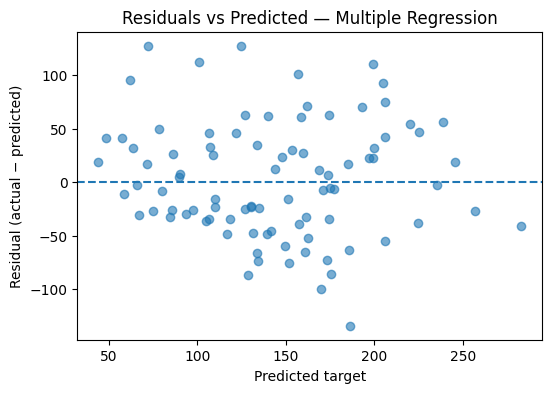

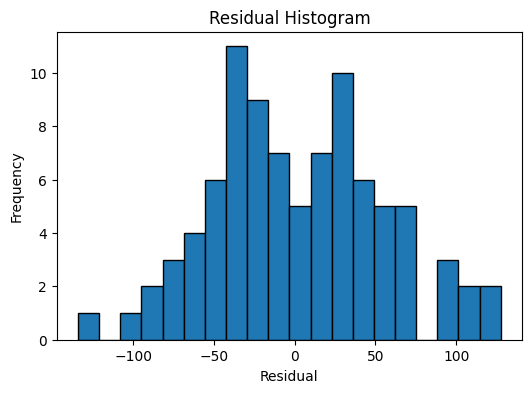

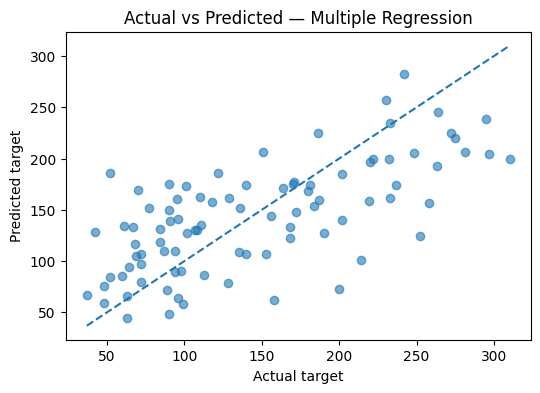

,Feature,VIF
0,bmi,1.425824
1,bp,1.299714
2,s5,1.507520
3,s6,1.423050


In [20]:
residuals = y_test - pred_multi

plt.figure(figsize=(6,4))
plt.scatter(pred_multi, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted — Multiple Regression")
plt.xlabel("Predicted target")
plt.ylabel("Residual (actual − predicted)")
plt.show()

plt.figure(figsize=(6,4))
plt.hist(residuals, bins=20, edgecolor="black")
plt.title("Residual Histogram")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(6,4))
plt.scatter(y_test, pred_multi, alpha=0.6)
lims = [min(y_test.min(), pred_multi.min()), max(y_test.max(), pred_multi.max())]
plt.plot(lims, lims, "--")
plt.title("Actual vs Predicted — Multiple Regression")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.show()

# VIF computed using statsmodels if available
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    X_vif = X_train.reset_index(drop=True)
    vif_table = pd.DataFrame({
        "Feature": X_vif.columns,
        "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
    })
    display(vif_table)
except ImportError:
    print("Install statsmodels to calculate VIF: !pip install statsmodels")

In [21]:
new_record = X_train.median().to_frame().T
new_prediction = multi_model.predict(new_record)[0]
print("New example (median feature values):")
display(new_record)
print(f"Predicted target: {new_prediction:.3f}")

print("\\nConclusion prompts:")
print("- Compare the multiple model against the single-feature model using test MAE/RMSE/R2.")
print("- Mention whether the extra features improved test performance enough to justify complexity.")
print("- Discuss residual patterns and multicollinearity/VIF.")
print("- State that linearity, independence, constant variance, normal residuals and no severe multicollinearity are assumptions to assess.")
print("- This educational model is not suitable for clinical decisions.")

New example (median feature values):


,bmi,bp,s5,s6
0,-0.005128,-0.00567,-0.000612,0.003064


Predicted target: 146.627
\nConclusion prompts:
- Compare the multiple model against the single-feature model using test MAE/RMSE/R2.
- Mention whether the extra features improved test performance enough to justify complexity.
- Discuss residual patterns and multicollinearity/VIF.
- State that linearity, independence, constant variance, normal residuals and no severe multicollinearity are assumptions to assess.
- This educational model is not suitable for clinical decisions.
